# Bank Name Matching Analysis: Banks Dataset vs Foursquare POIs

This notebook compares bank POIs between the UK Banks & Building Societies dataset and Foursquare.
For each bank/building society, we:
1. Match names (including common variations)
2. Count POIs in each dataset
3. Calculate median distance between matched locations
4. Identify POIs not within 50m of a match

In [1]:
import geopandas as gpd
from matplotlib.path import Path
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
# Load data

foursquare_pois = gpd.read_parquet("../../data/input_files/uk_foursquare_cc_nov_iceberg.parquet")
foursquare_pois["date_refreshed"] = pd.to_datetime(foursquare_pois["date_refreshed"])
#drop anything with a date_closed
foursquare_pois = foursquare_pois[foursquare_pois['date_closed'].isna()]

#load banks
banks = pd.read_parquet("data/UK_Banks_Building_Societies.parquet")
print(f"Initial banks dataset length: {len(banks)}")
#drop duplicates
banks = banks.drop_duplicates()
print(f"Length after dropping duplicates: {len(banks)}")
#save to parquet
banks.to_parquet("data/UK_Banks_Building_Societies_deduped.parquet", index=False)

Initial banks dataset length: 5875
Length after dropping duplicates: 5270


In [137]:
# Filter foursquare for banks only (fsq_category_id = 4bf58dd8d48988d10a951735)
foursquare_banks = foursquare_pois[foursquare_pois['fsq_category_id'] == '4bf58dd8d48988d10a951735'].copy()

# Convert banks data to GeoDataFrame
banks_gdf = gpd.GeoDataFrame(
    banks,
    geometry=gpd.points_from_xy(banks.longitude, banks.latitude),
    crs="EPSG:4326"
)

print(f"Foursquare banks: {len(foursquare_banks)}")
print(f"Banks dataset: {len(banks_gdf)}")

banks_gdf
#how many nationwide in the banks dataset
len(banks_gdf[banks_gdf['bank_bs'] == 'Nationwide Building Society'])
#are there duplicate nationwide entries in the banks dataset
banks_gdf[banks_gdf['bank_bs'] == 'Nationwide Building Society'].duplicated(subset=['longitude', 'latitude']).sum()

#drop the duplicate nationwide entries
banks_gdf = banks_gdf.drop_duplicates(subset=['bank_bs', 'longitude', 'latitude'])
#save ti bew

Foursquare banks: 13860
Banks dataset: 5270


In [138]:
# Define bank name mappings with common variations
# Map from banks dataset name -> list of possible Foursquare names
bank_name_mapping = {
    # Major banks
    'Barclays UK': ['Barclays'],
    'NWB': ['NatWest', 'Natwest', 'National Westminster Bank'],
    'RBS': ['RBS', 'R B S', 'Royal Bank of Scotland', 'The Royal Bank of Scotland'],
    'Lloyds Bank': ['Lloyds Bank', 'Lloyds', 'Lloyds Banking Group'],
    'Santander UK PLC': ['Santander', 'Santander UK'],
    'HSBC UK': ['HSBC', 'HSBC UK'],
    'Halifax': ['Halifax'],
    'TSB': ['TSB', 'TSB Bank'],
    'Bank of Scotland': ['Bank of Scotland'],
    'Virgin Money': ['Virgin Money'], # Yorkshire & Clydesdale merged with Virgin Money but dont include old names
    'Metro Bank': ['Metro Bank'],
    
    # Building societies
    'Nationwide Building Society': ['Nationwide', 'Nationwide Building Society'],
    'Yorkshire Building Society': ['Yorkshire Building Society'],
    'Coventry Building Society': ['Coventry Building Society'],
    'Skipton Building Society': ['Skipton Building Society'],
    'Principality Building Society': ['Principality Building Society'],
    'Leeds Building Society': ['Leeds Building Society'],
    'Newcastle Building Society': ['Newcastle Building Society'],
    'Nottingham Building Society': ['Nottingham Building Society', 'The Nottingham'],
    'Cumberland Building Society': ['Cumberland Building Society'],
    'Cambridge Building Society': ['Cambridge Building Society'],
    'Leek Building Society': ['Leek Building Society'],
    'Monmouthshire Building Society': ['Monmouthshire Building Society'],
    'Progressive Building Society': ['Progressive Building Society'],
    'Suffolk Building Society': ['Suffolk Building Society'],
    'Newbury Building Society': ['Newbury Building Society'],
    'Darlington Building Society': ['Darlington Building Society'],
    'Furness Building Society': ['Furness Building Society'],
    'Marsden Building Society': ['Marsden Building Society'],
    'Saffron Building Society': ['Saffron Building Society'],
    'West Brom Building Society': ['West Brom Building Society', 'West Bromwich Building Society', 'The West Brom'],
    'Hinkley and Rugby Building Society': ['Hinkley and Rugby Building Society'],
    'Dudley Building Society': ['Dudley Building Society'],
    'Scottish Building Society': ['Scottish Building Society'],
    'Hanley Economic Building Society': ['Hanley Economic Building Society'],
    'Vernon Building Society': ['Vernon Building Society'],
    'Market Harborough Building Society': ['Market Harborough Building Society'],
    'Loughborough Building Society': ['Loughborough Building Society'],
    'Harpenden Building Society': ['Harpenden Building Society'],
    'Melton Building Society': ['Melton Building Society'],
    'Mansfield Building Society': ['Mansfield Building Society'],
    'Tipton and Coseley Building Society': ['Tipton and Coseley Building Society'],
    'Swansea Building Society': ['Swansea Building Society'],
    'Chorley Building Society': ['Chorley Building Society'],
    'Bath Building Society': ['Bath Building Society'],
    'East Shipton Building Society': ['East Shipton Building Society'],
    'Beverley Building Society': ['Beverley Building Society'],
    'Stafford Building Society': ['Stafford Building Society'],
    'Penrith Building Society': ['Penrith Building Society'],
    
    # Other banks
    'Co-op': ['Co-op', 'The Co-operative Bank', 'Co-operative Bank'],
    'UBN': ['Ulster Bank', 'UBN'],
    'DanskeBank': ['Danske Bank', 'DanskeBank'],
    'Bank of Ireland (UK) Plc': ['Bank of Ireland'],
    'AIB (NI)': ['AIB', 'A I B', 'Allied Irish Bank', 'Aib Group'],
}

print(f"Defined name mappings for {len(bank_name_mapping)} banks/building societies")

#add a bank matched column to fou

Defined name mappings for 54 banks/building societies


In [139]:
# Identify unmatched Foursquare bank names
# Function to find which standardized name a POI matches
def find_matched_bank(poi_name, bank_name_mapping):
    """Returns the standardized bank name that this POI matches, or None if unmatched"""
    for standardized_name, patterns_list in bank_name_mapping.items():
        for pattern in patterns_list:
            if re.search(re.escape(pattern), poi_name, re.IGNORECASE):
                return standardized_name
    return None

# Apply the matching function
foursquare_banks['matched_bank'] = foursquare_banks['name'].apply(
    lambda x: find_matched_bank(x, bank_name_mapping)
)

# Separate matched and unmatched
unmatched_pois = foursquare_banks[foursquare_banks['matched_bank'].isna()].copy()

print(f"Total Foursquare bank POIs: {len(foursquare_banks):,}")
print(f"Matched by our mapping: {foursquare_banks['matched_bank'].notna().sum():,}")
print(f"Unmatched: {len(unmatched_pois):,} ({100*len(unmatched_pois)/len(foursquare_banks):.1f}%)")

# Get most common unmatched names
print("\n" + "="*60)
print("TOP 30 MOST COMMON UNMATCHED FOURSQUARE BANK NAMES")
print("="*60)
unmatched_counts = unmatched_pois['name'].value_counts().head(30)
for idx, (name, count) in enumerate(unmatched_counts.items(), 1):
    print(f"{idx:2d}. {name:40s} ({count:4,} POIs)")

Total Foursquare bank POIs: 13,860
Matched by our mapping: 10,298
Unmatched: 3,562 (25.7%)

TOP 30 MOST COMMON UNMATCHED FOURSQUARE BANK NAMES
 1. Western Union                            ( 412 POIs)
 2. Yorkshire Bank                           ( 216 POIs)
 3. Clydesdale Bank                          ( 213 POIs)
 4. Handelsbanken                            ( 173 POIs)
 5. Bradford & Bingley                       ( 139 POIs)
 6. Cheltenham & Gloucester                  (  77 POIs)
 7. Britannia Building Society               (  57 POIs)
 8. HFC Bank                                 (  47 POIs)
 9. Northern Bank                            (  39 POIs)
10. Beneficial Finance                       (  25 POIs)
11. Coutts                                   (  23 POIs)
12. First Trust Bank                         (  22 POIs)
13. Portman Building Society                 (  21 POIs)
14. Cheque Centre                            (  16 POIs)
15. Chelsea Building Society                 (  15 POIs)
16

In [140]:
# Helper functions for deduplication
def _norm_text(s: str) -> str:
    """Normalize text for comparison"""
    if s is None or pd.isna(s):
        return ""
    s = str(s).lower()
    s = re.sub(r"[^\w\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def _levenshtein(a: str, b: str) -> int:
    """Calculate Levenshtein distance between two strings"""
    if a == b: return 0
    if not a: return len(b)
    if not b: return len(a)
    if len(a) > len(b): a, b = b, a
    prev = list(range(len(a) + 1))
    for j, cb in enumerate(b, start=1):
        curr = [j]
        for i, ca in enumerate(a, start=1):
            curr.append(min(prev[i] + 1, curr[i - 1] + 1, prev[i - 1] + (ca != cb)))
        prev = curr
    return prev[-1]

def _lev_ratio(a: str, b: str) -> float:
    """Calculate similarity ratio (0-1) between two strings"""
    la, lb = len(a), len(b)
    if la == 0 and lb == 0:
        return 1.0
    return 1.0 - (_levenshtein(a, b) / max(la, lb))

def deduplicate_bank_pois(
    pois_gdf, 
    similar_address_distance_m=500,
    same_bank_distance_m=100,
    address_similarity_threshold=0.8
):
    """
    Deduplicate bank POIs using three rules (all require same matched_bank):
    1. Same bank + identical postcode → duplicate
    2. Same bank + similar address within similar_address_distance_m → duplicate
    3. Same bank within same_bank_distance_m → duplicate
    
    When duplicates found, keeps POI with most recent date_refreshed.
    
    Parameters:
    - pois_gdf: GeoDataFrame of POIs to deduplicate
    - similar_address_distance_m: Distance threshold for similar address rule (default 500m)
    - same_bank_distance_m: Distance threshold for same bank only rule (default 100m)
    - address_similarity_threshold: Similarity threshold for addresses (default 0.8)
    
    Returns:
    - Deduplicated GeoDataFrame, number of duplicates removed
    """
    if len(pois_gdf) == 0:
        return pois_gdf, 0
    
    # Project to metric CRS for distance calculations
    pois_proj = pois_gdf.to_crs("EPSG:27700").copy()
    
    # Prepare normalized columns
    pois_proj['addr_norm'] = pois_proj['address'].apply(_norm_text)
    pois_proj['postcode_norm'] = pois_proj['postcode'].apply(_norm_text)
    
    # Track indices to drop
    to_drop = set()
    
    # Use larger buffer to find all nearby POIs
    max_distance = max(same_bank_distance_m, similar_address_distance_m)
    pois_proj['buffer'] = pois_proj.geometry.buffer(max_distance)
    
    # Spatial join to find nearby pairs
    nearby_pairs = gpd.sjoin(
        pois_proj.set_geometry('buffer'),
        pois_proj[['geometry']],
        how='inner',
        predicate='contains'
    )
    
    # Only process each pair once (left index < right index)
    nearby_pairs = nearby_pairs[nearby_pairs.index < nearby_pairs.index_right]
    
    # Check each nearby pair against the three rules
    for idx, row in nearby_pairs.iterrows():
        left_idx = idx
        right_idx = row['index_right']
        
        # Skip if either already marked for deletion
        if left_idx in to_drop or right_idx in to_drop:
            continue
        
        # Get data for comparison
        left = pois_proj.loc[left_idx]
        right = pois_proj.loc[right_idx]
        
        # First check: must be same bank for any rule to apply
        if left['matched_bank'] != right['matched_bank']:
            continue
        
        distance_m = left.geometry.distance(right.geometry)
        
        is_duplicate = False
             # Rule 3: Same bank within tight distance threshold
        if distance_m <= same_bank_distance_m:
            is_duplicate = True
        # Rule 1: Same bank + identical postcode
        if left['postcode_norm'] and right['postcode_norm'] and left['postcode_norm'] == right['postcode_norm']:
            is_duplicate = True
        # Rule 2: Same bank + similar address within distance threshold
        elif distance_m <= similar_address_distance_m:
            addr_similarity = _lev_ratio(left['addr_norm'], right['addr_norm'])
            if addr_similarity >= address_similarity_threshold:
                is_duplicate = True
        
   
        
        if is_duplicate:
            # Keep the one with most recent date_refreshed
            left_date = pd.to_datetime(left['date_refreshed'])
            right_date = pd.to_datetime(right['date_refreshed'])
            
            if right_date > left_date:
                to_drop.add(left_idx)  # Keep right (newer), drop left
            else:
                to_drop.add(right_idx)  # Keep left (newer or same), drop right
    
    # Remove duplicates
    deduped = pois_gdf.drop(index=to_drop).copy()
    
    return deduped, len(to_drop)

print("Deduplication helper functions defined")

Deduplication helper functions defined


## Deduplication Stage

Deduplicate Foursquare banks data once, grouped by matched_bank, before running any analysis.

In [141]:
# Deduplicate Foursquare banks data
print("Deduplicating Foursquare bank POIs...")
print(f"Before deduplication: {len(foursquare_banks):,} POIs")

# Separate matched and unmatched POIs
matched_pois = foursquare_banks[foursquare_banks['matched_bank'].notna()].copy()
unmatched_pois_keep = foursquare_banks[foursquare_banks['matched_bank'].isna()].copy()
print(f"  Matched POIs to deduplicate: {len(matched_pois):,}")
print(f"  Unmatched POIs (kept as-is): {len(unmatched_pois_keep):,}")

# Deduplicate all matched POIs together (function handles same bank check internally)
if len(matched_pois) > 0:
    deduped_matched, total_duplicates_removed = deduplicate_bank_pois(
        matched_pois,
        similar_address_distance_m=500,
        same_bank_distance_m=100,
        address_similarity_threshold=0.6
    )
    print(f"  Total duplicates removed: {total_duplicates_removed:,}")
else:
    deduped_matched = matched_pois
    total_duplicates_removed = 0

# Combine deduplicated matched POIs with unmatched POIs
foursquare_banks_deduped = pd.concat([deduped_matched, unmatched_pois_keep], ignore_index=False)

print(f"\nAfter deduplication: {len(foursquare_banks_deduped):,} POIs")
print(f"Total duplicates removed: {total_duplicates_removed:,}")

# Replace original with deduplicated version
foursquare_banks = foursquare_banks_deduped.copy()

Deduplicating Foursquare bank POIs...
Before deduplication: 13,860 POIs
  Matched POIs to deduplicate: 10,298
  Unmatched POIs (kept as-is): 3,562
  Total duplicates removed: 377

After deduplication: 13,483 POIs
Total duplicates removed: 377


In [142]:
# foursquare_banks["matched_bank"] == 'Lloyds Bank'
fsq_lloyds = foursquare_banks[
    foursquare_banks['matched_bank'] == 'Lloyds Bank'
].copy()
fsq_lloyds

#loop through and find distance to nearest in same frame and add to the df
fsq_lloyds['nearest_dist_m'] = None
fsq_lloyds_proj = fsq_lloyds.to_crs("EPSG:27700").copy()
for idx, row in fsq_lloyds_proj.iterrows():
    geom = row['geometry']
    other_pois = fsq_lloyds_proj.drop(index=idx)
    if len(other_pois) == 0:
        continue
    # Calculate distances to all other POIs
    other_pois['dist_m'] = other_pois.geometry.distance(geom)
    # Get minimum distance
    min_dist = other_pois['dist_m'].min()
    fsq_lloyds.loc[idx, 'nearest_dist_m'] = min_dist
fsq_lloyds = fsq_lloyds.sort_values(by='nearest_dist_m', ascending=True)
fsq_lloyds

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,matched_bank,nearest_dist_m
1058779,717361f8191e4adabb2e74ae,Lloyds TSB Bank,53.104811,-2.019941,9 The Smithfield Centre,Leek,Staffordshire,ST13 5JW,England,Leek,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,103.060094
1058813,4e3a8068b61c8493db54f33c,Lloyds Bank,53.105704,-2.020355,15 Fountain St,Leek,Staffordshire,ST13 6JS,England,None,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,103.060094
1736199,4e312578b61c03a1e7d917c9,Lloyds TSB Bank,51.274296,0.523234,18 Week St,Maidstone,Kent,ME14 1RW,England,None,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,118.914452
1736089,88a46671309940bf43020696,Lloyds TSB Bank,51.274772,0.521709,17 Earl St,Maidstone,Kent,ME14 1XY,England,Maidstone,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,118.914452
750636,07d72e8e3c36423d50415a6d,Lloyds TSB Bank,53.837876,-1.638761,2 Feast Field 1st Floor,Horsforth,West Yorkshire,LS18 4TJ,England,Leeds,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,124.042195
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2234164,4d95fe0a0caaa143fdda6bb3,Lloyds Bank,52.414859,-4.082285,None,None,None,None,None,None,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,50752.526803
4407831,54150ca53069471e3e251b3b,Lloyds TSB Bank,56.462601,-2.970621,19 Albert Square,Dundee,Angus,DD1 1DA,Scotland,None,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,54658.172218
4680867,4e1db92caeb78c0dfecfa5e3,Lloyds Bank,57.482041,-4.211275,None,Inverness,Highland,None,Scotland,None,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,127496.298901
1860284,c3bdf7d3aef347b73ac5af1f,Lloyds TSB Bank,54.578525,-5.940429,A 73 Malone Rd,Belfast,Belfast,BT9 6SB,Northern Ireland,Belfast,...,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank,128738.371585


In [143]:
# Helper function to compute spatial matches and distances
def analyze_bank_matches(bank_name, fsq_name_patterns, banks_gdf, foursquare_banks):
    """
    For a given bank, find all POIs in both datasets and compute spatial statistics.
    Note: Deduplication should already be done on foursquare_banks before calling this function.
    
    Returns:
        dict with keys: bank_name, banks_count, fsq_count, median_dist_m, 
                       banks_unmatched_100m, fsq_unmatched_100m
    """
    # Filter banks dataset
    bank_pois = banks_gdf[banks_gdf['bank_bs'] == bank_name].copy()
    
    # Filter foursquare dataset (match any of the name patterns)
    # Data is already deduplicated
    fsq_pois = foursquare_banks[
        foursquare_banks['name'].str.contains('|'.join(fsq_name_patterns), case=False, na=False, regex=True)
    ].copy()
    
    banks_count = len(bank_pois)
    fsq_count = len(fsq_pois)
    
    # If either dataset is empty, return early
    if banks_count == 0 or fsq_count == 0:
        return {
            'bank_name': bank_name,
            'banks_count': banks_count,
            'fsq_count': fsq_count,
            'median_dist_m': np.nan,
            'banks_unmatched_100m': banks_count if fsq_count == 0 else 0,
            'fsq_unmatched_100m': fsq_count if banks_count == 0 else 0
        }
    
    # Project to British National Grid for distance calculations
    proj_crs = "EPSG:27700"
    bank_pois_proj = bank_pois.to_crs(proj_crs)
    fsq_pois_proj = fsq_pois.to_crs(proj_crs)
    
    # Find nearest Foursquare POI for each bank POI
    joined = gpd.sjoin_nearest(
        bank_pois_proj,
        fsq_pois_proj,
        how="left",
        distance_col="dist_m"
    )
    
    # Calculate median distance
    median_dist = joined['dist_m'].median()
    
    # Count banks not within 100m
    banks_unmatched_100m = (joined['dist_m'] > 100).sum()
    
    # Find nearest bank POI for each Foursquare POI (reverse direction)
    joined_reverse = gpd.sjoin_nearest(
        fsq_pois_proj,
        bank_pois_proj,
        how="left",
        distance_col="dist_m"
    )
    
    # Count Foursquare POIs not within 100m
    fsq_unmatched_100m = (joined_reverse['dist_m'] > 100).sum()
    
    return {
        'bank_name': bank_name,
        'banks_count': banks_count,
        'fsq_count': fsq_count,
        'median_dist_m': median_dist,
        'banks_unmatched_100m': banks_unmatched_100m,
        'fsq_unmatched_100m': fsq_unmatched_100m
    }

print("Helper function defined")

Helper function defined


In [144]:
# Run analysis for all banks in the mapping
results = []

for bank_name, fsq_patterns in bank_name_mapping.items():
    print(f"Analyzing {bank_name}...")
    result = analyze_bank_matches(bank_name, fsq_patterns, banks_gdf, foursquare_banks)
    results.append(result)

# Convert to DataFrame for easier viewing
results_df = pd.DataFrame(results)

# Sort by banks_count descending
results_df = results_df.sort_values('banks_count', ascending=False)

print(f"\nAnalyzed {len(results_df)} banks/building societies")
results_df



Analyzing Barclays UK...
Analyzing NWB...
Analyzing RBS...
Analyzing Lloyds Bank...
Analyzing Santander UK PLC...
Analyzing HSBC UK...
Analyzing Halifax...
Analyzing TSB...
Analyzing Bank of Scotland...
Analyzing Virgin Money...
Analyzing Metro Bank...
Analyzing Nationwide Building Society...
Analyzing Yorkshire Building Society...
Analyzing Coventry Building Society...
Analyzing Skipton Building Society...
Analyzing Principality Building Society...
Analyzing Leeds Building Society...
Analyzing Newcastle Building Society...
Analyzing Nottingham Building Society...
Analyzing Cumberland Building Society...
Analyzing Cambridge Building Society...
Analyzing Leek Building Society...
Analyzing Monmouthshire Building Society...
Analyzing Progressive Building Society...
Analyzing Suffolk Building Society...
Analyzing Newbury Building Society...
Analyzing Darlington Building Society...
Analyzing Furness Building Society...
Analyzing Marsden Building Society...
Analyzing Saffron Building Society

,bank_name,banks_count,fsq_count,median_dist_m,banks_unmatched_100m,fsq_unmatched_100m
0,Barclays UK,721,1301,155.829561,438,1019
1,NWB,679,1523,101.627969,342,1187
11,Nationwide Building Society,605,744,3.049070,17,156
2,RBS,465,584,9795.107862,399,518
3,Lloyds Bank,407,1164,9.825427,41,798
4,Santander UK PLC,368,851,22.748642,39,522
5,HSBC UK,327,1287,15.300902,28,988
6,Halifax,287,643,20.887314,37,392
12,Yorkshire Building Society,220,214,30.450004,54,48
7,TSB,217,1072,18.239013,48,886


In [145]:
# Add proportion columns to results
results_df['prop_banks_matched'] = (results_df['banks_count'] - results_df['banks_unmatched_100m']) / results_df['banks_count']
results_df['prop_fsq_matched'] = (results_df['fsq_count'] - results_df['fsq_unmatched_100m']) / results_df['fsq_count']

# Replace inf/nan with 0
results_df['prop_banks_matched'] = results_df['prop_banks_matched'].fillna(0).replace([np.inf, -np.inf], 0)
results_df['prop_fsq_matched'] = results_df['prop_fsq_matched'].fillna(0).replace([np.inf, -np.inf], 0)

results_df

,bank_name,banks_count,fsq_count,median_dist_m,banks_unmatched_100m,fsq_unmatched_100m,prop_banks_matched,prop_fsq_matched
0,Barclays UK,721,1301,155.829561,438,1019,0.392510,0.216756
1,NWB,679,1523,101.627969,342,1187,0.496318,0.220617
11,Nationwide Building Society,605,744,3.049070,17,156,0.971901,0.790323
2,RBS,465,584,9795.107862,399,518,0.141935,0.113014
3,Lloyds Bank,407,1164,9.825427,41,798,0.899263,0.314433
4,Santander UK PLC,368,851,22.748642,39,522,0.894022,0.386604
5,HSBC UK,327,1287,15.300902,28,988,0.914373,0.232323
6,Halifax,287,643,20.887314,37,392,0.871080,0.390358
12,Yorkshire Building Society,220,214,30.450004,54,48,0.754545,0.775701
7,TSB,217,1072,18.239013,48,886,0.778802,0.173507


## Key Findings

This analysis compares bank locations between the UK Banks & Building Societies dataset and Foursquare POI data.

**Methodology:**
- Name matching uses common variations (e.g., "NatWest", "Natwest" for NWB)
- Spatial matching uses nearest neighbor within British National Grid projection
- 50m threshold used to determine if POIs are "matched"

**Metrics explained:**
- **POI counts**: Total number of locations in each dataset
- **Median distance**: Median distance from each Banks dataset POI to its nearest Foursquare match
- **Not within 50m**: Count of POIs that don't have a match within 50 meters

**Interpretation:**
- Low median distance indicates good spatial agreement between datasets
- High "not within 50m" counts suggest missing data or location inaccuracies
- Foursquare may have more POIs due to including ATMs, closed branches, or different categorization

# Analysis with Recent Foursquare Data Only (2025+)

Now rerunning the analysis using only Foursquare POIs with date_refreshed after 2025-01-01.
This filters for the most recently updated/verified bank locations.

In [147]:
# Filter Foursquare banks for date_refreshed >= 2025-01-01
cutoff_date = pd.Timestamp('2025-01-01')

foursquare_banks_recent = foursquare_banks[
    foursquare_banks['date_refreshed'] >= cutoff_date
].copy()

print(f"Original Foursquare bank POIs: {len(foursquare_banks):,}")
print(f"Recent (2025+) Foursquare bank POIs: {len(foursquare_banks_recent):,}")
print(f"Filtered out: {len(foursquare_banks) - len(foursquare_banks_recent):,} ({100*(len(foursquare_banks) - len(foursquare_banks_recent))/len(foursquare_banks):.1f}%)")

# Show date_refreshed distribution for recent data
print("\nDate distribution of recent POIs:")
print(foursquare_banks_recent['date_refreshed'].describe())

Original Foursquare bank POIs: 13,483
Recent (2025+) Foursquare bank POIs: 6,773
Filtered out: 6,710 (49.8%)

Date distribution of recent POIs:
count                             6773
mean     2025-07-02 08:44:17.611102720
min                2025-01-02 00:00:00
25%                2025-06-07 00:00:00
50%                2025-07-03 00:00:00
75%                2025-07-18 00:00:00
max                2025-10-11 00:00:00
Name: date_refreshed, dtype: object


## Analysis with Multiple Date Cutoffs

Running analysis with different date cutoffs for comparison: 2010+, 2015+, 2020+, 2024+, 2025+

In [148]:
# Filter Foursquare banks for multiple date cutoffs
cutoff_date_2010 = pd.Timestamp('2010-01-01')
cutoff_date_2015 = pd.Timestamp('2015-01-01')
cutoff_date_2020 = pd.Timestamp('2020-01-01')
cutoff_date_2024 = pd.Timestamp('2024-01-01')

foursquare_banks_2010 = foursquare_banks[foursquare_banks['date_refreshed'] >= cutoff_date_2010].copy()
foursquare_banks_2015 = foursquare_banks[foursquare_banks['date_refreshed'] >= cutoff_date_2015].copy()
foursquare_banks_2020 = foursquare_banks[foursquare_banks['date_refreshed'] >= cutoff_date_2020].copy()
foursquare_banks_2024 = foursquare_banks[foursquare_banks['date_refreshed'] >= cutoff_date_2024].copy()

print(f"Original Foursquare bank POIs: {len(foursquare_banks):,}")
print(f"2010+ Foursquare bank POIs: {len(foursquare_banks_2010):,}")
print(f"2015+ Foursquare bank POIs: {len(foursquare_banks_2015):,}")
print(f"2020+ Foursquare bank POIs: {len(foursquare_banks_2020):,}")
print(f"2024+ Foursquare bank POIs: {len(foursquare_banks_2024):,}")
print(f"2025+ Foursquare bank POIs: {len(foursquare_banks_recent):,}")
print(f"\nFiltered out (2010 cutoff): {len(foursquare_banks) - len(foursquare_banks_2010):,} ({100*(len(foursquare_banks) - len(foursquare_banks_2010))/len(foursquare_banks):.1f}%)")
print(f"Filtered out (2015 cutoff): {len(foursquare_banks) - len(foursquare_banks_2015):,} ({100*(len(foursquare_banks) - len(foursquare_banks_2015))/len(foursquare_banks):.1f}%)")
print(f"Filtered out (2020 cutoff): {len(foursquare_banks) - len(foursquare_banks_2020):,} ({100*(len(foursquare_banks) - len(foursquare_banks_2020))/len(foursquare_banks):.1f}%)")
print(f"Filtered out (2024 cutoff): {len(foursquare_banks) - len(foursquare_banks_2024):,} ({100*(len(foursquare_banks) - len(foursquare_banks_2024))/len(foursquare_banks):.1f}%)")
print(f"Filtered out (2025 cutoff): {len(foursquare_banks) - len(foursquare_banks_recent):,} ({100*(len(foursquare_banks) - len(foursquare_banks_recent))/len(foursquare_banks):.1f}%)")

Original Foursquare bank POIs: 13,483
2010+ Foursquare bank POIs: 13,483
2015+ Foursquare bank POIs: 12,528
2020+ Foursquare bank POIs: 10,825
2024+ Foursquare bank POIs: 8,837
2025+ Foursquare bank POIs: 6,773

Filtered out (2010 cutoff): 0 (0.0%)
Filtered out (2015 cutoff): 955 (7.1%)
Filtered out (2020 cutoff): 2,658 (19.7%)
Filtered out (2024 cutoff): 4,646 (34.5%)
Filtered out (2025 cutoff): 6,710 (49.8%)


In [149]:
# Run analysis for 2010+ data
results_2010 = []
for bank_name, fsq_patterns in bank_name_mapping.items():
    print(f"Analyzing {bank_name} (2010+ data)...")
    result = analyze_bank_matches(bank_name, fsq_patterns, banks_gdf, foursquare_banks_2010)
    results_2010.append(result)

results_2010_df = pd.DataFrame(results_2010)
results_2010_df = results_2010_df.sort_values('banks_count', ascending=False)
results_2010_df['prop_banks_matched'] = (results_2010_df['banks_count'] - results_2010_df['banks_unmatched_100m']) / results_2010_df['banks_count']
results_2010_df['prop_fsq_matched'] = (results_2010_df['fsq_count'] - results_2010_df['fsq_unmatched_100m']) / results_2010_df['fsq_count']
results_2010_df['prop_banks_matched'] = results_2010_df['prop_banks_matched'].fillna(0).replace([np.inf, -np.inf], 0)
results_2010_df['prop_fsq_matched'] = results_2010_df['prop_fsq_matched'].fillna(0).replace([np.inf, -np.inf], 0)
print(f"\nAnalyzed {len(results_2010_df)} banks/building societies (2010+ data)")

Analyzing Barclays UK (2010+ data)...
Analyzing NWB (2010+ data)...
Analyzing RBS (2010+ data)...
Analyzing Lloyds Bank (2010+ data)...
Analyzing Santander UK PLC (2010+ data)...
Analyzing HSBC UK (2010+ data)...
Analyzing Halifax (2010+ data)...
Analyzing TSB (2010+ data)...
Analyzing Bank of Scotland (2010+ data)...
Analyzing Virgin Money (2010+ data)...
Analyzing Metro Bank (2010+ data)...
Analyzing Nationwide Building Society (2010+ data)...
Analyzing Yorkshire Building Society (2010+ data)...
Analyzing Coventry Building Society (2010+ data)...
Analyzing Skipton Building Society (2010+ data)...
Analyzing Principality Building Society (2010+ data)...
Analyzing Leeds Building Society (2010+ data)...
Analyzing Newcastle Building Society (2010+ data)...
Analyzing Nottingham Building Society (2010+ data)...
Analyzing Cumberland Building Society (2010+ data)...
Analyzing Cambridge Building Society (2010+ data)...
Analyzing Leek Building Society (2010+ data)...
Analyzing Monmouthshire Bui

In [150]:
# Run analysis for 2015+ data
results_2015 = []
for bank_name, fsq_patterns in bank_name_mapping.items():
    print(f"Analyzing {bank_name} (2015+ data)...")
    result = analyze_bank_matches(bank_name, fsq_patterns, banks_gdf, foursquare_banks_2015)
    results_2015.append(result)

results_2015_df = pd.DataFrame(results_2015)
results_2015_df = results_2015_df.sort_values('banks_count', ascending=False)
results_2015_df['prop_banks_matched'] = (results_2015_df['banks_count'] - results_2015_df['banks_unmatched_100m']) / results_2015_df['banks_count']
results_2015_df['prop_fsq_matched'] = (results_2015_df['fsq_count'] - results_2015_df['fsq_unmatched_100m']) / results_2015_df['fsq_count']
results_2015_df['prop_banks_matched'] = results_2015_df['prop_banks_matched'].fillna(0).replace([np.inf, -np.inf], 0)
results_2015_df['prop_fsq_matched'] = results_2015_df['prop_fsq_matched'].fillna(0).replace([np.inf, -np.inf], 0)
print(f"\nAnalyzed {len(results_2015_df)} banks/building societies (2015+ data)")

Analyzing Barclays UK (2015+ data)...
Analyzing NWB (2015+ data)...
Analyzing RBS (2015+ data)...
Analyzing Lloyds Bank (2015+ data)...
Analyzing Santander UK PLC (2015+ data)...
Analyzing HSBC UK (2015+ data)...
Analyzing Halifax (2015+ data)...
Analyzing TSB (2015+ data)...
Analyzing Bank of Scotland (2015+ data)...
Analyzing Virgin Money (2015+ data)...
Analyzing Metro Bank (2015+ data)...
Analyzing Nationwide Building Society (2015+ data)...
Analyzing Yorkshire Building Society (2015+ data)...
Analyzing Coventry Building Society (2015+ data)...
Analyzing Skipton Building Society (2015+ data)...
Analyzing Principality Building Society (2015+ data)...
Analyzing Leeds Building Society (2015+ data)...
Analyzing Newcastle Building Society (2015+ data)...
Analyzing Nottingham Building Society (2015+ data)...
Analyzing Cumberland Building Society (2015+ data)...
Analyzing Cambridge Building Society (2015+ data)...
Analyzing Leek Building Society (2015+ data)...
Analyzing Monmouthshire Bui

In [151]:
# Run analysis for 2020+ data
results_2020 = []
for bank_name, fsq_patterns in bank_name_mapping.items():
    print(f"Analyzing {bank_name} (2020+ data)...")
    result = analyze_bank_matches(bank_name, fsq_patterns, banks_gdf, foursquare_banks_2020)
    results_2020.append(result)

results_2020_df = pd.DataFrame(results_2020)
results_2020_df = results_2020_df.sort_values('banks_count', ascending=False)
results_2020_df['prop_banks_matched'] = (results_2020_df['banks_count'] - results_2020_df['banks_unmatched_100m']) / results_2020_df['banks_count']
results_2020_df['prop_fsq_matched'] = (results_2020_df['fsq_count'] - results_2020_df['fsq_unmatched_100m']) / results_2020_df['fsq_count']
results_2020_df['prop_banks_matched'] = results_2020_df['prop_banks_matched'].fillna(0).replace([np.inf, -np.inf], 0)
results_2020_df['prop_fsq_matched'] = results_2020_df['prop_fsq_matched'].fillna(0).replace([np.inf, -np.inf], 0)
print(f"\nAnalyzed {len(results_2020_df)} banks/building societies (2020+ data)")

Analyzing Barclays UK (2020+ data)...
Analyzing NWB (2020+ data)...
Analyzing RBS (2020+ data)...
Analyzing Lloyds Bank (2020+ data)...
Analyzing Santander UK PLC (2020+ data)...
Analyzing HSBC UK (2020+ data)...
Analyzing Halifax (2020+ data)...
Analyzing TSB (2020+ data)...
Analyzing Bank of Scotland (2020+ data)...
Analyzing Virgin Money (2020+ data)...
Analyzing Metro Bank (2020+ data)...
Analyzing Nationwide Building Society (2020+ data)...
Analyzing Yorkshire Building Society (2020+ data)...
Analyzing Coventry Building Society (2020+ data)...
Analyzing Skipton Building Society (2020+ data)...
Analyzing Principality Building Society (2020+ data)...
Analyzing Leeds Building Society (2020+ data)...
Analyzing Newcastle Building Society (2020+ data)...
Analyzing Nottingham Building Society (2020+ data)...
Analyzing Cumberland Building Society (2020+ data)...
Analyzing Cambridge Building Society (2020+ data)...
Analyzing Leek Building Society (2020+ data)...
Analyzing Monmouthshire Bui

In [152]:
# Run analysis for all banks using 2024+ Foursquare data
results_2024 = []

for bank_name, fsq_patterns in bank_name_mapping.items():
    print(f"Analyzing {bank_name} (2024+ data)...")
    result = analyze_bank_matches(bank_name, fsq_patterns, banks_gdf, foursquare_banks_2024)
    results_2024.append(result)

# Convert to DataFrame
results_2024_df = pd.DataFrame(results_2024)

# Sort by banks_count descending
results_2024_df = results_2024_df.sort_values('banks_count', ascending=False)

# Add proportion columns
results_2024_df['prop_banks_matched'] = (results_2024_df['banks_count'] - results_2024_df['banks_unmatched_100m']) / results_2024_df['banks_count']
results_2024_df['prop_fsq_matched'] = (results_2024_df['fsq_count'] - results_2024_df['fsq_unmatched_100m']) / results_2024_df['fsq_count']
results_2024_df['prop_banks_matched'] = results_2024_df['prop_banks_matched'].fillna(0).replace([np.inf, -np.inf], 0)
results_2024_df['prop_fsq_matched'] = results_2024_df['prop_fsq_matched'].fillna(0).replace([np.inf, -np.inf], 0)

print(f"\nAnalyzed {len(results_2024_df)} banks/building societies (2024+ data)")
results_2024_df

Analyzing Barclays UK (2024+ data)...
Analyzing NWB (2024+ data)...
Analyzing RBS (2024+ data)...
Analyzing Lloyds Bank (2024+ data)...
Analyzing Santander UK PLC (2024+ data)...
Analyzing HSBC UK (2024+ data)...
Analyzing Halifax (2024+ data)...
Analyzing TSB (2024+ data)...
Analyzing Bank of Scotland (2024+ data)...
Analyzing Virgin Money (2024+ data)...
Analyzing Metro Bank (2024+ data)...
Analyzing Nationwide Building Society (2024+ data)...
Analyzing Yorkshire Building Society (2024+ data)...
Analyzing Coventry Building Society (2024+ data)...
Analyzing Skipton Building Society (2024+ data)...
Analyzing Principality Building Society (2024+ data)...
Analyzing Leeds Building Society (2024+ data)...
Analyzing Newcastle Building Society (2024+ data)...
Analyzing Nottingham Building Society (2024+ data)...
Analyzing Cumberland Building Society (2024+ data)...
Analyzing Cambridge Building Society (2024+ data)...
Analyzing Leek Building Society (2024+ data)...
Analyzing Monmouthshire Bui

,bank_name,banks_count,fsq_count,median_dist_m,banks_unmatched_100m,fsq_unmatched_100m,prop_banks_matched,prop_fsq_matched
0,Barclays UK,721,866,287.197253,498,643,0.309293,0.257506
1,NWB,679,1466,106.050106,346,1134,0.490427,0.226467
11,Nationwide Building Society,605,728,3.128843,26,149,0.957025,0.795330
2,RBS,465,341,14097.332192,419,295,0.098925,0.134897
3,Lloyds Bank,407,700,16.691872,134,427,0.670762,0.390000
4,Santander UK PLC,368,549,41.168942,136,317,0.630435,0.422587
5,HSBC UK,327,634,33.105386,128,435,0.608563,0.313880
6,Halifax,287,197,3069.213918,179,89,0.376307,0.548223
12,Yorkshire Building Society,220,160,58.060400,95,35,0.568182,0.781250
7,TSB,217,823,19.090597,54,644,0.751152,0.217497


In [153]:
# Check matched vs unmatched in recent data
matched_recent = foursquare_banks_recent['matched_bank'].notna().sum()
unmatched_recent = foursquare_banks_recent['matched_bank'].isna().sum()

print(f"Matched banks in recent data: {matched_recent:,} ({100*matched_recent/len(foursquare_banks_recent):.1f}%)")
print(f"Unmatched banks in recent data: {unmatched_recent:,} ({100*unmatched_recent/len(foursquare_banks_recent):.1f}%)")

# Top matched banks in recent data
print("\nTop 10 matched banks in recent (2025+) data:")
print(foursquare_banks_recent['matched_bank'].value_counts().head(10))

Matched banks in recent data: 4,893 (72.2%)
Unmatched banks in recent data: 1,880 (27.8%)

Top 10 matched banks in recent (2025+) data:
matched_bank
Barclays UK                    691
NWB                            677
Lloyds Bank                    645
HSBC UK                        544
Nationwide Building Society    531
Santander UK PLC               435
RBS                            246
TSB                            246
Yorkshire Building Society     128
Halifax                        112
Name: count, dtype: int64


In [154]:
# Run analysis for all banks using RECENT Foursquare data only
results_recent = []

for bank_name, fsq_patterns in bank_name_mapping.items():
    print(f"Analyzing {bank_name} (recent data)...")
    result = analyze_bank_matches(bank_name, fsq_patterns, banks_gdf, foursquare_banks_recent)
    results_recent.append(result)

# Convert to DataFrame
results_recent_df = pd.DataFrame(results_recent)

# Sort by banks_count descending
results_recent_df = results_recent_df.sort_values('banks_count', ascending=False)

print(f"\nAnalyzed {len(results_recent_df)} banks/building societies (recent data)")
results_recent_df

Analyzing Barclays UK (recent data)...
Analyzing NWB (recent data)...
Analyzing RBS (recent data)...
Analyzing Lloyds Bank (recent data)...
Analyzing Santander UK PLC (recent data)...
Analyzing HSBC UK (recent data)...
Analyzing Halifax (recent data)...
Analyzing TSB (recent data)...
Analyzing Bank of Scotland (recent data)...
Analyzing Virgin Money (recent data)...
Analyzing Metro Bank (recent data)...
Analyzing Nationwide Building Society (recent data)...
Analyzing Yorkshire Building Society (recent data)...
Analyzing Coventry Building Society (recent data)...
Analyzing Skipton Building Society (recent data)...
Analyzing Principality Building Society (recent data)...
Analyzing Leeds Building Society (recent data)...
Analyzing Newcastle Building Society (recent data)...
Analyzing Nottingham Building Society (recent data)...
Analyzing Cumberland Building Society (recent data)...
Analyzing Cambridge Building Society (recent data)...
Analyzing Leek Building Society (recent data)...
Analy

,bank_name,banks_count,fsq_count,median_dist_m,banks_unmatched_100m,fsq_unmatched_100m
0,Barclays UK,721,691,540.530411,521,491
1,NWB,679,677,2304.022433,487,487
11,Nationwide Building Society,605,531,4.466577,135,61
2,RBS,465,246,18630.814837,434,215
3,Lloyds Bank,407,645,20.698289,156,394
4,Santander UK PLC,368,435,71.719403,176,243
5,HSBC UK,327,544,91.148111,161,378
6,Halifax,287,112,7564.580119,225,50
12,Yorkshire Building Society,220,128,348.842090,115,23
7,TSB,217,808,19.999588,56,632


In [155]:
# Add proportion columns to recent results
results_recent_df['prop_banks_matched'] = (results_recent_df['banks_count'] - results_recent_df['banks_unmatched_100m']) / results_recent_df['banks_count']
results_recent_df['prop_fsq_matched'] = (results_recent_df['fsq_count'] - results_recent_df['fsq_unmatched_100m']) / results_recent_df['fsq_count']
results_recent_df['prop_banks_matched'] = results_recent_df['prop_banks_matched'].fillna(0).replace([np.inf, -np.inf], 0)
results_recent_df['prop_fsq_matched'] = results_recent_df['prop_fsq_matched'].fillna(0).replace([np.inf, -np.inf], 0)

print("Proportion columns added to results_recent_df")

Proportion columns added to results_recent_df


In [ ]:
# Comprehensive Comparison: All Cutoffs
print("="*120)
print("COMPREHENSIVE COMPARISON: NO CUTOFF vs 2010+ vs 2015+ vs 2020+ vs 2024+ vs 2025+")
print("="*120)

# Create comprehensive comparison dataframe
comp_full = results_df[['bank_name', 'banks_count']].copy()

# Add data from all analyses
for suffix, df in [('_all', results_df), ('_2010', results_2010_df), ('_2015', results_2015_df), 
                   ('_2020', results_2020_df), ('_2024', results_2024_df), ('_2025', results_recent_df)]:
    comp_full = comp_full.merge(
        df[['bank_name', 'fsq_count', 'prop_banks_matched', 'prop_fsq_matched', 'median_dist_m']],
        on='bank_name',
        how='left',
        suffixes=('', suffix)
    )

# Rename columns for clarity
comp_full.columns = [
    'bank_name', 'banks_count',
    'fsq_all', 'prop_banks_matched_all', 'prop_fsq_matched_all', 'median_dist_all',
    'fsq_2010', 'prop_banks_matched_2010', 'prop_fsq_matched_2010', 'median_dist_2010',
    'fsq_2015', 'prop_banks_matched_2015', 'prop_fsq_matched_2015', 'median_dist_2015',
    'fsq_2020', 'prop_banks_matched_2020', 'prop_fsq_matched_2020', 'median_dist_2020',
    'fsq_2024', 'prop_banks_matched_2024', 'prop_fsq_matched_2024', 'median_dist_2024',
    'fsq_2025', 'prop_banks_matched_2025', 'prop_fsq_matched_2025', 'median_dist_2025'
]

# Sort by banks_count descending
comp_full = comp_full.sort_values('banks_count', ascending=False)

# Display top 15 banks with BOTH match rates
print("\nTop 15 Banks - Match Rates in Both Directions:")
print("-" * 120)
print(f"{'Bank':<30} {'Type':<5} {'Count':<7} {'All':<7} {'2010+':<7} {'2015+':<7} {'2020+':<7} {'2024+':<7} {'2025+':<7}")
print("=" * 120)

for idx, row in comp_full.head(15).iterrows():
    bank_name = row['bank_name'][:28]
    banks_count = row['banks_count']
    fsq_count = row['fsq_all'] if pd.notna(row['fsq_all']) else 0
    
    # Banks match rates
    banks_all = row['prop_banks_matched_all'] * 100 if pd.notna(row['prop_banks_matched_all']) else 0
    banks_2010 = row['prop_banks_matched_2010'] * 100 if pd.notna(row['prop_banks_matched_2010']) else 0
    banks_2015 = row['prop_banks_matched_2015'] * 100 if pd.notna(row['prop_banks_matched_2015']) else 0
    banks_2020 = row['prop_banks_matched_2020'] * 100 if pd.notna(row['prop_banks_matched_2020']) else 0
    banks_2024 = row['prop_banks_matched_2024'] * 100 if pd.notna(row['prop_banks_matched_2024']) else 0
    banks_2025 = row['prop_banks_matched_2025'] * 100 if pd.notna(row['prop_banks_matched_2025']) else 0
    
    # Foursquare match rates
    fsq_all = row['prop_fsq_matched_all'] * 100 if pd.notna(row['prop_fsq_matched_all']) else 0
    fsq_2010 = row['prop_fsq_matched_2010'] * 100 if pd.notna(row['prop_fsq_matched_2010']) else 0
    fsq_2015 = row['prop_fsq_matched_2015'] * 100 if pd.notna(row['prop_fsq_matched_2015']) else 0
    fsq_2020 = row['prop_fsq_matched_2020'] * 100 if pd.notna(row['prop_fsq_matched_2020']) else 0
    fsq_2024 = row['prop_fsq_matched_2024'] * 100 if pd.notna(row['prop_fsq_matched_2024']) else 0
    fsq_2025 = row['prop_fsq_matched_2025'] * 100 if pd.notna(row['prop_fsq_matched_2025']) else 0
    
    # Print Banks row
    print(f"{bank_name:<30} {'Bank':<5} {banks_count:<7,} {banks_all:>5.1f}% {banks_2010:>5.1f}% {banks_2015:>5.1f}% {banks_2020:>5.1f}% {banks_2024:>5.1f}% {banks_2025:>5.1f}%")
    # Print FSQ row
    print(f"{'':<30} {'FSQ':<5} {fsq_count:<7,.0f} {fsq_all:>5.1f}% {fsq_2010:>5.1f}% {fsq_2015:>5.1f}% {fsq_2020:>5.1f}% {fsq_2024:>5.1f}% {fsq_2025:>5.1f}%")
    print("-" * 120)

# Overall statistics
print("\n" + "="*120)
print("OVERALL STATISTICS ACROSS ALL SCENARIOS")
print("="*120)

for label, df in [('No Cutoff (All Data)', results_df), ('2010+ Data', results_2010_df), 
                  ('2015+ Data', results_2015_df), ('2020+ Data', results_2020_df),
                  ('2024+ Data', results_2024_df), ('2025+ Data', results_recent_df)]:
    print(f"\n{label}:")
    print(f"  Total Banks POIs: {df['banks_count'].sum():,}")
    print(f"  Total Foursquare POIs: {df['fsq_count'].sum():,}")
    print(f"  Banks Match Rate: {100*(df['banks_count'].sum() - df['banks_unmatched_100m'].sum())/df['banks_count'].sum():.1f}%")
    print(f"  Foursquare Match Rate: {100*(df['fsq_count'].sum() - df['fsq_unmatched_100m'].sum())/df['fsq_count'].sum():.1f}%")
    print(f"  Median distance: {df['median_dist_m'].median():.1f}m")

# Save comprehensive comparison
comp_full.to_csv("data/bank_matching_comprehensive_comparison.csv", index=False)
print("\n" + "="*120)
print("Comprehensive comparison saved to: data/bank_matching_comprehensive_comparison.csv")

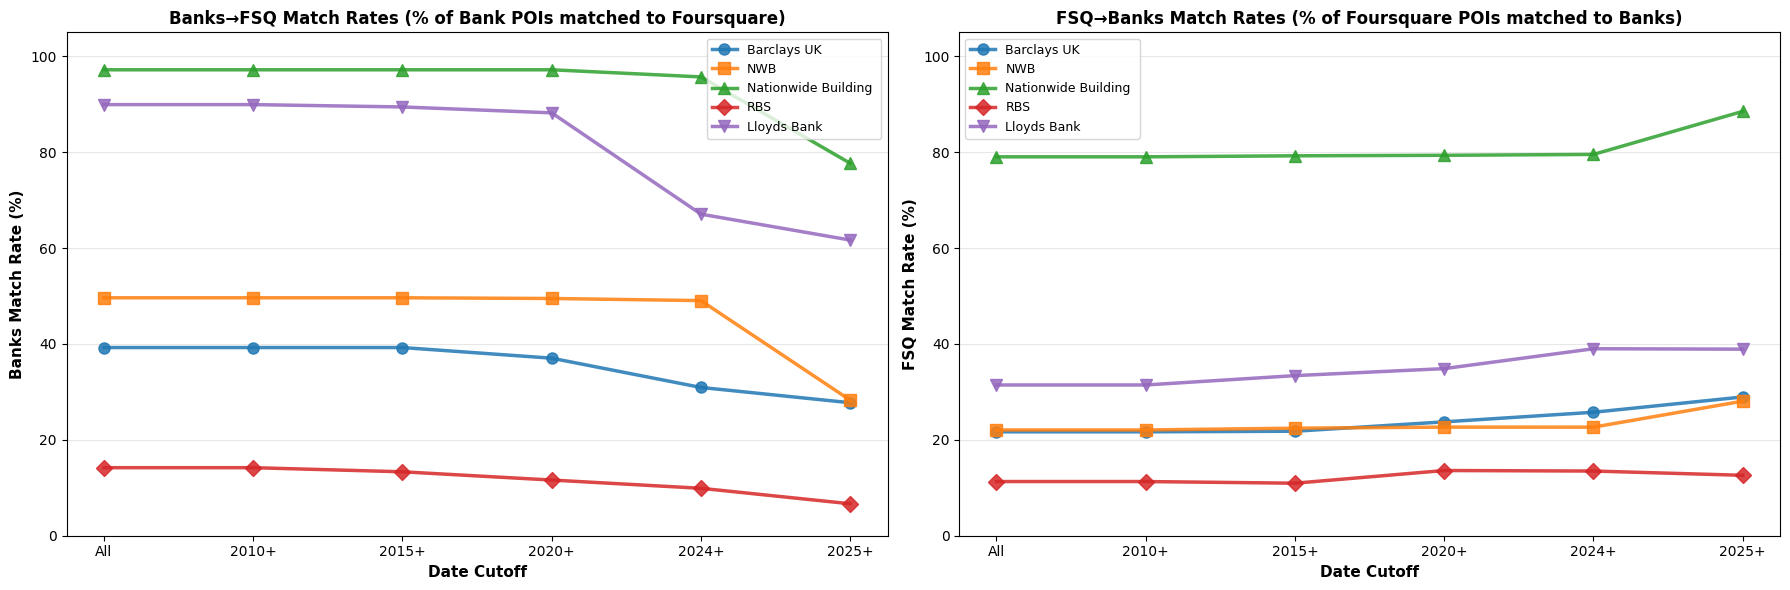

In [ ]:
# Visualizations comparing all scenarios - SIMPLIFIED
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Select top 5 banks for visualization
top5_comp = comp_full.head(5).copy()
scenarios = ['All', '2010+', '2015+', '2020+', '2024+', '2025+']

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
markers = ['o', 's', '^', 'D', 'v']

# 1. Banks→FSQ Match Rates (Top 5 Banks)
ax1 = axes[0]

for i, bank_idx in enumerate(top5_comp.index):
    bank_row = top5_comp.loc[bank_idx]
    bank_name = bank_row['bank_name'][:20]
    
    # Get Banks match rates for each scenario
    match_rates = [
        bank_row['prop_banks_matched_all'] * 100 if pd.notna(bank_row['prop_banks_matched_all']) else 0,
        bank_row['prop_banks_matched_2010'] * 100 if pd.notna(bank_row['prop_banks_matched_2010']) else 0,
        bank_row['prop_banks_matched_2015'] * 100 if pd.notna(bank_row['prop_banks_matched_2015']) else 0,
        bank_row['prop_banks_matched_2020'] * 100 if pd.notna(bank_row['prop_banks_matched_2020']) else 0,
        bank_row['prop_banks_matched_2024'] * 100 if pd.notna(bank_row['prop_banks_matched_2024']) else 0,
        bank_row['prop_banks_matched_2025'] * 100 if pd.notna(bank_row['prop_banks_matched_2025']) else 0
    ]
    
    ax1.plot(scenarios, match_rates, marker=markers[i], linewidth=2.5, markersize=8,
             label=bank_name, color=colors[i], alpha=0.85)

ax1.set_xlabel('Date Cutoff', fontsize=11, fontweight='bold')
ax1.set_ylabel('Banks Match Rate (%)', fontsize=11, fontweight='bold')
ax1.set_title('Banks→FSQ Match Rates (% of Bank POIs matched to Foursquare)', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9, loc='best')
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, 105)

# 2. FSQ→Banks Match Rates (Top 5 Banks)
ax2 = axes[1]

for i, bank_idx in enumerate(top5_comp.index):
    bank_row = top5_comp.loc[bank_idx]
    bank_name = bank_row['bank_name'][:20]
    
    # Get FSQ match rates for each scenario
    match_rates = [
        bank_row['prop_fsq_matched_all'] * 100 if pd.notna(bank_row['prop_fsq_matched_all']) else 0,
        bank_row['prop_fsq_matched_2010'] * 100 if pd.notna(bank_row['prop_fsq_matched_2010']) else 0,
        bank_row['prop_fsq_matched_2015'] * 100 if pd.notna(bank_row['prop_fsq_matched_2015']) else 0,
        bank_row['prop_fsq_matched_2020'] * 100 if pd.notna(bank_row['prop_fsq_matched_2020']) else 0,
        bank_row['prop_fsq_matched_2024'] * 100 if pd.notna(bank_row['prop_fsq_matched_2024']) else 0,
        bank_row['prop_fsq_matched_2025'] * 100 if pd.notna(bank_row['prop_fsq_matched_2025']) else 0
    ]
    
    ax2.plot(scenarios, match_rates, marker=markers[i], linewidth=2.5, markersize=8,
             label=bank_name, color=colors[i], alpha=0.85)

ax2.set_xlabel('Date Cutoff', fontsize=11, fontweight='bold')
ax2.set_ylabel('FSQ Match Rate (%)', fontsize=11, fontweight='bold')
ax2.set_title('FSQ→Banks Match Rates (% of Foursquare POIs matched to Banks)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9, loc='best')
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.savefig('data/bank_matching_summary_graphs.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Save all results to CSV with proportion columns
results_export = results_df.copy()
results_export['median_dist_m'] = results_export['median_dist_m'].round(1)
results_export['prop_banks_matched'] = results_export['prop_banks_matched'].round(3)
results_export['prop_fsq_matched'] = results_export['prop_fsq_matched'].round(3)
results_export.to_csv("data/bank_name_foursquare_matching_analysis_all.csv", index=False)

results_2010_export = results_2010_df.copy()
results_2010_export['median_dist_m'] = results_2010_export['median_dist_m'].round(1)
results_2010_export['prop_banks_matched'] = results_2010_export['prop_banks_matched'].round(3)
results_2010_export['prop_fsq_matched'] = results_2010_export['prop_fsq_matched'].round(3)
results_2010_export.to_csv("data/bank_name_foursquare_matching_analysis_2010.csv", index=False)

results_2015_export = results_2015_df.copy()
results_2015_export['median_dist_m'] = results_2015_export['median_dist_m'].round(1)
results_2015_export['prop_banks_matched'] = results_2015_export['prop_banks_matched'].round(3)
results_2015_export['prop_fsq_matched'] = results_2015_export['prop_fsq_matched'].round(3)
results_2015_export.to_csv("data/bank_name_foursquare_matching_analysis_2015.csv", index=False)

results_2020_export = results_2020_df.copy()
results_2020_export['median_dist_m'] = results_2020_export['median_dist_m'].round(1)
results_2020_export['prop_banks_matched'] = results_2020_export['prop_banks_matched'].round(3)
results_2020_export['prop_fsq_matched'] = results_2020_export['prop_fsq_matched'].round(3)
results_2020_export.to_csv("data/bank_name_foursquare_matching_analysis_2020.csv", index=False)

results_2024_export = results_2024_df.copy()
results_2024_export['median_dist_m'] = results_2024_export['median_dist_m'].round(1)
results_2024_export['prop_banks_matched'] = results_2024_export['prop_banks_matched'].round(3)
results_2024_export['prop_fsq_matched'] = results_2024_export['prop_fsq_matched'].round(3)
results_2024_export.to_csv("data/bank_name_foursquare_matching_analysis_2024.csv", index=False)

results_recent_export = results_recent_df.copy()
results_recent_export['median_dist_m'] = results_recent_export['median_dist_m'].round(1)
results_recent_export['prop_banks_matched'] = results_recent_export['prop_banks_matched'].round(3)
results_recent_export['prop_fsq_matched'] = results_recent_export['prop_fsq_matched'].round(3)
results_recent_export.to_csv("data/bank_name_foursquare_matching_analysis_2025.csv", index=False)

print("All analysis results saved!")
print(f"\nFiles saved:")
print("  1. data/bank_name_foursquare_matching_analysis_all.csv (no date cutoff)")
print("  2. data/bank_name_foursquare_matching_analysis_2010.csv (2010+ data)")
print("  3. data/bank_name_foursquare_matching_analysis_2015.csv (2015+ data)")
print("  4. data/bank_name_foursquare_matching_analysis_2020.csv (2020+ data)")
print("  5. data/bank_name_foursquare_matching_analysis_2024.csv (2024+ data)")
print("  6. data/bank_name_foursquare_matching_analysis_2025.csv (2025+ data)")
print("  7. data/bank_matching_comprehensive_comparison.csv (side-by-side comparison)")
print("\nColumns in each file:")
print("  - bank_name: Name of bank/building society")
print("  - banks_count: Number of branches in Banks dataset")
print("  - fsq_count: Number of POIs in Foursquare (after deduplication)")
print("  - median_dist_m: Median distance between matched POIs (meters)")
print("  - banks_unmatched_100m: Number of bank branches >100m from nearest Foursquare POI")
print("  - fsq_unmatched_100m: Number of Foursquare POIs >100m from nearest bank branch")
print("  - prop_banks_matched: Proportion of bank branches matched to Foursquare (0-1)")
print("  - prop_fsq_matched: Proportion of Foursquare POIs matched to bank branches (0-1)")

In [ ]:
#look at lloyds banks in the foursquare
fsq_lloyds = foursquare_banks[
    foursquare_banks['matched_bank'] == 'Lloyds Bank'
].copy()

In [ ]:
fsq_lloyds

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,matched_bank
2459,4e874a6ad22d194bded1d756,Lloyds Bank,52.931090,1.298727,None,Cromer,Norfolk,None,England,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
6367,4ec141cd2c5b252c1a46e151,Lloyds Bank,52.821226,1.386387,None,None,Norfolk,None,England,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
10407,ae23e979f4fc4ec242480647,Lloyds TSB Bank,52.900145,1.080118,1-5 High St,Holt,Norfolk,NR25 6BN,England,Holt,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
15206,5e8b5dab84643d00081e6ede,Lloyds Bank,52.753397,0.395782,21-23 High Street,Kings lynn,Norfolk,PE30 1BP,England,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
21239,5e8b5e0886d36d00082b436d,Lloyds Bank,53.143107,0.339163,51 Lumley Road,Skegness,Lincolnshire,PE25 3LP,England,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4584708,60f1d1ee882dd225613d29a1,Lloyds TSB Bank,55.856245,-4.342106,Braehead Shopping Centre,Glasgow,None,G51 4HS,Scotland,Glasgow,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
4585276,4e92ca52e5fa72f70fdd1a39,Lloyds Bank,55.845897,-4.357022,None,None,None,None,None,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
4665565,4f393838e4b00af17bd2f855,Lloyds Bank,55.460876,-4.639865,None,None,None,None,None,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
4680867,4e1db92caeb78c0dfecfa5e3,Lloyds Bank,57.482041,-4.211275,None,Inverness,Highland,None,Scotland,None,...,Financial Service,63be6904847c3692a84b9b3f,Banking and Finance,4bf58dd8d48988d10a951735,Bank,None,None,None,None,Lloyds Bank
